# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms

In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [3]:
x_train = data['train_images']
y_train = data['train_labels']

x_val = data['val_images']
y_val = data['val_labels']

x_test = data['test_images']
y_test = data['test_labels']

In [4]:
print("--- STRUKTURA I KANAŁY ---")

print(f"Kształt x_train: {x_train.shape}")
print(f"Pojedynczy obrazek ma wymiary: {x_train.shape[1]}x{x_train.shape[2]} pikseli")
print(f"Liczba kanałów (3 oznacza kolor RGB): {x_train.shape[3]}")

print("\n--- KLASY I LICZEBNOŚĆ ---")
y_train_flat = y_train.ravel() 
klasy, zliczenia = np.unique(y_train_flat, return_counts=True)
print(f"Dostępne etykiety klas: {klasy}")
print(f"Liczba unikalnych klas: {len(klasy)}")

df_counts = pd.DataFrame({'Klasa': klasy, 'Liczba próbek': zliczenia})
display(df_counts)

print("\n--- JAKOŚĆ DANYCH ---")
print(f"Minimalna wartość piksela: {x_train.min()} (oczekiwane 0)")
print(f"Maksymalna wartość piksela: {x_train.max()} (oczekiwane 255)")
czy_sa_nany = np.isnan(x_train).any()
print(f"Czy są puste wartości (NaN) w obrazach? {czy_sa_nany}")

--- STRUKTURA I KANAŁY ---
Kształt x_train: (11959, 28, 28, 3)
Pojedynczy obrazek ma wymiary: 28x28 pikseli
Liczba kanałów (3 oznacza kolor RGB): 3

--- KLASY I LICZEBNOŚĆ ---
Dostępne etykiety klas: [0 1 2 3 4 5 6 7]
Liczba unikalnych klas: 8


,Klasa,Liczba próbek
0,0,852
1,1,2181
2,2,1085
3,3,2026
4,4,849
5,5,993
6,6,2330
7,7,1643



--- JAKOŚĆ DANYCH ---
Minimalna wartość piksela: 0 (oczekiwane 0)
Maksymalna wartość piksela: 255 (oczekiwane 255)
Czy są puste wartości (NaN) w obrazach? False


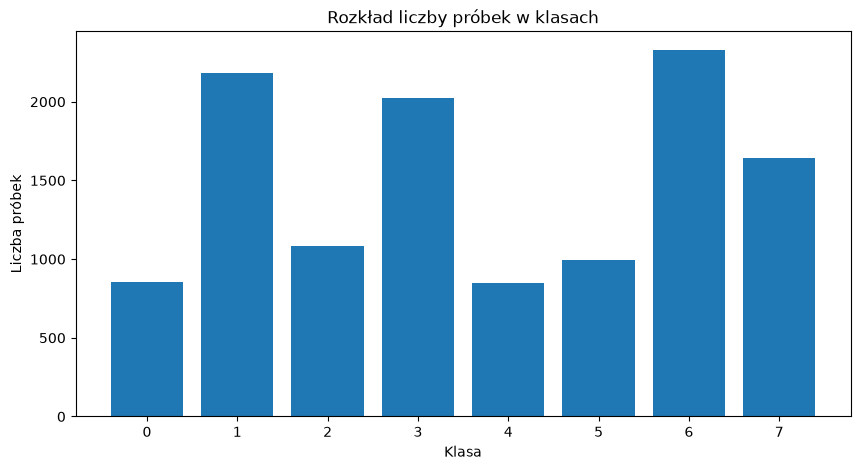

In [5]:
#wykres klas
plt.figure(figsize=(10, 5))
plt.bar(klasy, zliczenia)
plt.xlabel('Klasa')
plt.ylabel('Liczba próbek')
plt.title('Rozkład liczby próbek w klasach')
plt.show()


dosyć spore niezbalansowanie klas

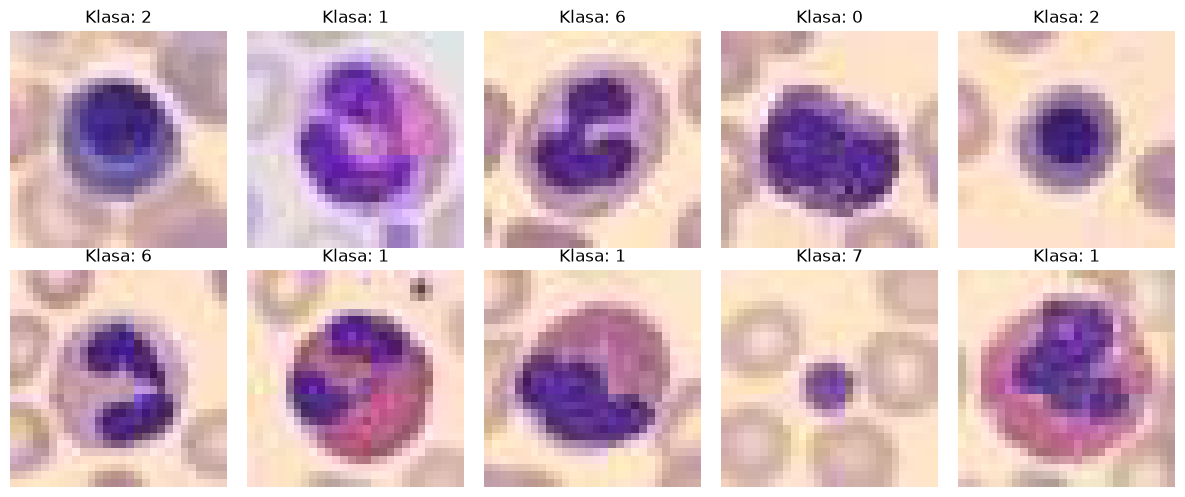

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

axes = axes.flatten()

for i in range(10):
    random_idx = np.random.randint(0, len(x_train))
    
    img = x_train[random_idx]
    label = y_train[random_idx]
    
    axes[i].imshow(img)
    
    class_id = label[0] if isinstance(label, np.ndarray) else label
    axes[i].set_title(f"Klasa: {class_id}")
    
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [7]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.ToTensor()
])


In [8]:
class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        lab = self.labels[idx].squeeze()

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(lab, dtype=torch.long)
        

In [9]:


train_dataset = BloodMNISTDataset(x_train, y_train, train_transforms)
val_dataset = BloodMNISTDataset(x_val, y_val, test_transforms)
test_dataset = BloodMNISTDataset(x_test, y_test, test_transforms)

class_counts = np.bincount(y_train.ravel())
class_weights = 1.0 / class_counts
sample_weights = [class_weights[label] for label in y_train.ravel()]

sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

BATCH_SIZE = 64

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, sampler=sampler)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)



## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [10]:
class BloodCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=1568, out_features=128),
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=8)
        )

    def forward(self, x):
        temp = self.features(x)
        return self.classifier(temp)


model = BloodCNN()


In [11]:
import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Obliczenia będą wykonywane na: {device}")

model = BloodCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)


Obliczenia będą wykonywane na: cpu


In [12]:
EPOCHS = 15
best_val_acc = 0.0

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_acc = 100 * correct / total

    print(f"Epoka {epoch+1:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_blood_model.pth")

        print(f" ---> Zapisano nowy najlepszy model! (Skuteczność: {val_acc:.2f}%)")
       

Epoka 01/15 | Train Loss: 1.3919 | Val Loss: 1.0557 | Val Acc: 59.17%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 59.17%)
Epoka 02/15 | Train Loss: 0.9768 | Val Loss: 0.8291 | Val Acc: 67.93%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 67.93%)
Epoka 03/15 | Train Loss: 0.8644 | Val Loss: 0.7991 | Val Acc: 69.68%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 69.68%)
Epoka 04/15 | Train Loss: 0.7820 | Val Loss: 0.7330 | Val Acc: 71.61%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 71.61%)
Epoka 05/15 | Train Loss: 0.7209 | Val Loss: 0.6115 | Val Acc: 77.63%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 77.63%)
Epoka 06/15 | Train Loss: 0.6655 | Val Loss: 0.6077 | Val Acc: 77.92%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 77.92%)
Epoka 07/15 | Train Loss: 0.6110 | Val Loss: 0.5090 | Val Acc: 82.36%
 ---> Zapisano nowy najlepszy model! (Skuteczność: 82.36%)
Epoka 08/15 | Train Loss: 0.5488 | Val Loss: 0.4426 | Val Acc: 84.00%
 ---> Zapisano nowy najleps

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

Raport klasyfikacji:
              precision    recall  f1-score   support

     Klasa 0       0.60      0.86      0.71       244
     Klasa 1       0.93      0.98      0.95       624
     Klasa 2       0.90      0.89      0.90       311
     Klasa 3       0.74      0.69      0.71       579
     Klasa 4       0.92      0.74      0.82       243
     Klasa 5       0.80      0.63      0.71       284
     Klasa 6       0.93      0.95      0.94       666
     Klasa 7       1.00      0.99      0.99       470

    accuracy                           0.86      3421
   macro avg       0.85      0.84      0.84      3421
weighted avg       0.87      0.86      0.86      3421



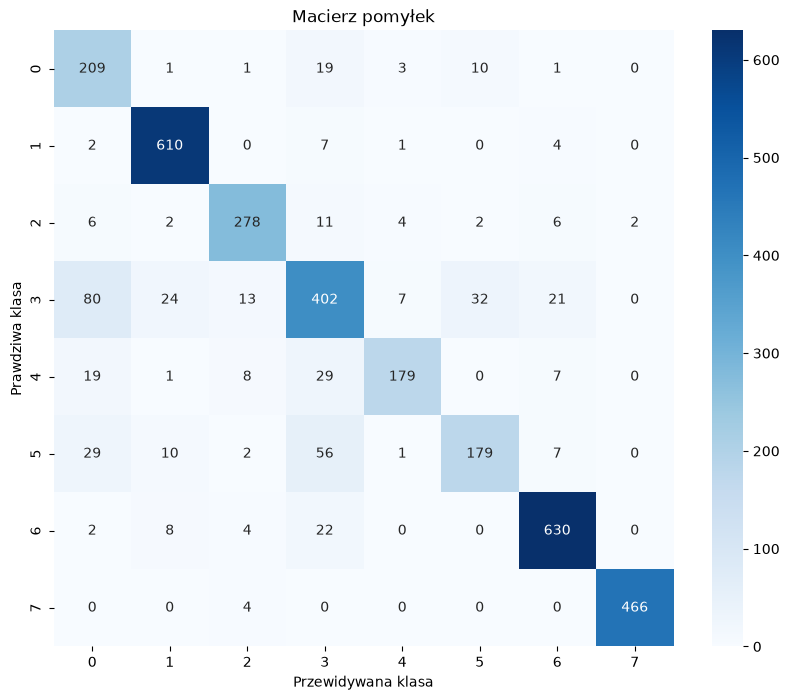

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.load_state_dict(torch.load("best_blood_model.pth"))
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

print("Raport klasyfikacji:")
print(classification_report(y_true, y_pred, target_names=[f"Klasa {i}" for i in range(8)]))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=klasy, yticklabels=klasy)
plt.xlabel('Przewidywana klasa')
plt.ylabel('Prawdziwa klasa')
plt.title('Macierz pomyłek')
plt.show()

In [ ]:
# !pip install grad-cam
# !pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


c:\Users\jakub\iCloudDrive\Studia\ai med\Rekrutacja-AI-Med-2026-2027\.venv\Scripts\python.exe: No module named pip


  Using cached numpy-2.2.6-cp314-cp314-win_amd64.whl
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.4
    Uninstalling numpy-2.3.4:
      Successfully uninstalled numpy-2.3.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas 3.0.0 requires numpy>=2.3.3; python_version >= "3.14", but you have numpy 2.2.6 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jakub\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


--- WYJAŚNIALNOŚĆ MODELU (Grad-CAM) ---


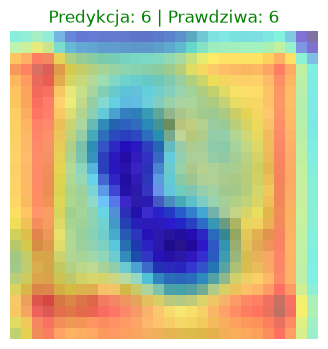

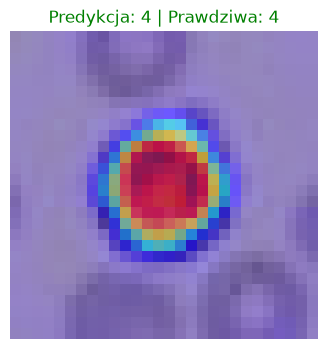

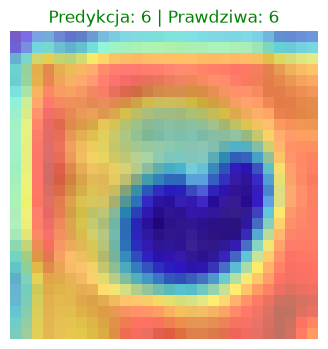

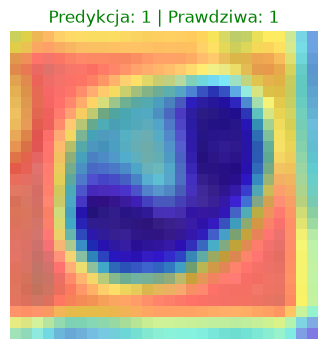

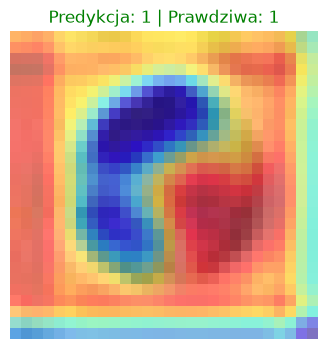

In [20]:
import cv2
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


target_layers = [model.features[3]]
cam = GradCAM(model=model, target_layers=target_layers)

def visualize_prediction(index, dataset, model, cam):
    image_tensor, label = dataset[index]
    image_tensor = image_tensor.unsqueeze(0).to(device) 
    
    model.eval()
    outputs = model(image_tensor)
    _, predicted = torch.max(outputs.data, 1)
    
    targets = [ClassifierOutputTarget(predicted.item())]
    grayscale_cam = cam(input_tensor=image_tensor, targets=targets)[0, :]
    
    img_np = image_tensor.cpu().squeeze().permute(1, 2, 0).numpy()
    
    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)
    
    plt.figure(figsize=(4, 4))
    plt.imshow(visualization)
    tytul = f"Predykcja: {predicted.item()} | Prawdziwa: {label.item()}"
    if predicted.item() == label.item():
        plt.title(tytul, color="green")
    else:
        plt.title(tytul, color="red")
    plt.axis('off')
    plt.show()

print("--- WYJAŚNIALNOŚĆ MODELU (Grad-CAM) ---")
for _ in range(5):
    random_index = np.random.randint(0, len(test_dataset))
    visualize_prediction(random_index, test_dataset, model, cam)

Zastosowaną metodą wizualnego wyjaśniania modelu jest algorytm **Grad-CAM** (Gradient-weighted Class Activation Mapping). Pozwala on na stworzenie "mapy ciepła" poprzez analizę gradientów przepływających do ostatniej warstwy splotowej (w przypadku naszego modelu: warstwa `self.features[3]`).

**Ograniczenia zastosowanej metody:**
1. **Niska rozdzielczość mapy cech:** Ze względu na specyfikę architektury CNN z warstwami `MaxPool2d` oraz bardzo mały rozmiar początkowy obrazów (28x28 pikseli), ostatnia warstwa splotowa ma rozmiar zaledwie 7x7. Grad-CAM interpoluje tę małą mapę z powrotem do 28x28, co sprawia, że podświetlenia są zgrubne ("rozmyte") i nie pozwalają na dokładną analizę na poziomie pojedynczych organelli czy cienkich krawędzi.
2. **Brak wskazania natury cechy:** Grad-CAM pokazuje jedynie, *gdzie* model "patrzył", ale nie wyjaśnia, *czego* tam szukał (czy decyzję podjął na podstawie koloru, kształtu krawędzi, czy wielkości jądra komórkowego). Może to prowadzić do błędnych interpretacji klinicznych (np. lekarz i model patrzą na ten sam fragment komórki, ale wyciągają wnioski z innych jej parametrów).
3. **Nie skupia się na samych komórkach:** Tylko na drugiej heatmapie widać, że czerwona plama znajduje się faktycznie na komórce, a nie na jej otoczeniu jak w reszcie przykładów. Możliwe, że model nauczył się jakiś innych zależności, niekoniecznie wynikających z biologii samych komórek.


## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.